# **1. Herramienta ydata-profiling**

In [1]:
# 1. Instalar la librería en Colab
!pip install ydata-profiling -q



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 2.0 MB/s eta 0:00:00


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
# 2. Importar las librerías
import pandas as pd
from ydata_profiling import ProfileReport
from google.colab import files

# 3. Cargar tus datos desde Google Drive
df = pd.read_csv("/content/drive/MyDrive/Ejercicios Aplicación ML/adult.csv")

# 4. Generar el reporte
reporte = ProfileReport(df, title="Reporte Completo Colab", explorative=True)
reporte.to_file("diagnostico_ydata.html")

# 5. Descargar el reporte automáticamente
files.download("diagnostico_ydata.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 15/15 [00:01<00:00, 11.22it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **2. Herramienta Sweetviz**

In [10]:
!pip install sweetviz -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 49.4 MB/s eta 0:00:00


In [12]:
# 1. Instalar la librería en Colab
!pip install sweetviz -q

# 2. Importar las librerías necesarias
import pandas as pd
import sweetviz as sv
from google.colab import files

# 3. Cargar el dataset Adult (Asegúrate de subir el archivo con este nombre exacto)
df = pd.read_csv("/content/drive/MyDrive/Ejercicios Aplicación ML/adult.csv")

# 4. Identificar tu columna objetivo categórica.
# NOTA: Si en tu archivo la columna se llama 'class' o 'salary', cambia "income" por ese nombre.
columna_objetivo = "income"

# 5. Limpieza y preparación para Sweetviz:
# Eliminamos espacios en blanco accidentales que suelen venir en este dataset (ej. " <=50K")
df[columna_objetivo] = df[columna_objetivo].astype(str).str.strip()

# Mapeamos la categoría a booleano (0 y 1) para activar las mejores gráficas de Sweetviz
df[columna_objetivo] = df[columna_objetivo].map({"<=50K": 0, ">50K": 1})

# Si hay filas donde la variable objetivo quedó vacía, las borramos
df = df.dropna(subset=[columna_objetivo])

# 6. Generar el reporte automatizado
# Sweetviz usará el 1 (>50K) como el evento de interés para comparar todo el dataset
reporte_adult = sv.analyze(df, target_feat=columna_objetivo)
reporte_adult.show_html("reporte_adult_sweetviz.html", open_browser=False)

# 7. Descargar el reporte automáticamente a tu computadora
files.download("reporte_adult_sweetviz.html")


                                             |          | [  0%]   00:00 -> (? left)

Report reporte_adult_sweetviz.html was generated.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **3. Metodo CLASS para reutilizacion**

In [16]:
%%writefile herramientas_eda.py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class AutoEDA:
    def __init__(self, df: pd.DataFrame, target_col: str = None):
        """
        Inicializa la clase con el DataFrame y la columna objetivo (opcional).
        """
        self.df = df
        self.target_col = target_col
        self.num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
        self.cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

    def _diagnose_missing_and_duplicates(self):
        print("=== 1. DIAGNÓSTICO DE CALIDAD DE DATOS ===")
        # Duplicados
        duplicates = self.df.duplicated().sum()
        print(f" Filas duplicadas: {duplicates} ({duplicates / len(self.df) * 100:.2f}%)")

        # Valores nulos
        missing = self.df.isnull().sum()
        missing = missing[missing > 0]
        if missing.empty:
            print(" No se encontraron valores nulos (NaN/None).\n")
        else:
            print(" Valores nulos por columna:")
            for col, val in missing.items():
                print(f"  - {col}: {val} nulos ({val / len(self.df) * 100:.2f}%)")
            print()

    def _summary_statistics(self):
        print("=== 2. RESUMEN ESTADÍSTICO ===")
        print(f"Variables numéricas ({len(self.num_cols)}): {self.num_cols}")
        print(f"Variables categóricas ({len(self.cat_cols)}): {self.cat_cols}\n")

        print("Estadísticas de variables numéricas:")
        print(self.df[self.num_cols].describe().T[['mean', 'std', 'min', '50%', 'max']])
        print()

    def _detect_outliers(self):
        print("=== 3. DETECCIÓN DE OUTLIERS (IQR) ===")
        for col in self.num_cols:
            Q1 = self.df[col].quantile(0.25)
            Q3 = self.df[col].quantile(0.75)
            IQR = Q3 - Q1
            outliers = ((self.df[col] < (Q1 - 1.5 * IQR)) | (self.df[col] > (Q3 + 1.5 * IQR))).sum()
            print(f"  - {col}: {outliers} outliers detectados ({outliers / len(self.df) * 100:.2f}%)")
        print()

    def _correlation_analysis(self):
        print("=== 4. MATRIZ DE CORRELACIÓN DE PEARSON ===")
        if len(self.num_cols) > 1:
            corr = self.df[self.num_cols].corr()
            plt.figure(figsize=(8, 6))
            sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
            plt.title("Matriz de Correlación")
            plt.tight_layout()
            plt.show()
        else:
            print(" No hay suficientes variables numéricas para calcular correlaciones.")
        print()

    def run_analysis(self):
        """
        MÉTODO PRINCIPAL: Dispara el flujo completo de análisis del dataset.
        """
        print(f"INICIANDO ANÁLISIS AUTOMÁTICO DE DATOS ({self.df.shape[0]} filas, {self.df.shape[1]} columnas)\n" + "="*60)
        self._diagnose_missing_and_duplicates()
        self._summary_statistics()
        self._detect_outliers()
        self._correlation_analysis()
        print("="*60 + "\nANÁLISIS COMPLETADO CON ÉXITO.")




Overwriting herramientas_eda.py


# 3.1 Uso de CLASS

In [18]:
from herramientas_eda import AutoEDA

INICIANDO ANÁLISIS AUTOMÁTICO DE DATOS (32561 filas, 15 columnas)
=== 1. DIAGNÓSTICO DE CALIDAD DE DATOS ===
 Filas duplicadas: 24 (0.07%)
 No se encontraron valores nulos (NaN/None).

=== 2. RESUMEN ESTADÍSTICO ===
Variables numéricas (6): ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Variables categóricas (9): ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country', 'income']

Estadísticas de variables numéricas:
                         mean            std      min       50%        max
age                 38.581647      13.640433     17.0      37.0       90.0
fnlwgt          189778.366512  105549.977697  12285.0  178356.0  1484705.0
education-num       10.080679       2.572720      1.0      10.0       16.0
capital-gain      1077.648844    7385.292085      0.0       0.0    99999.0
capital-loss        87.303830     402.960219      0.0       0.0     4356.0
hours-per-week      40.437456      12.347

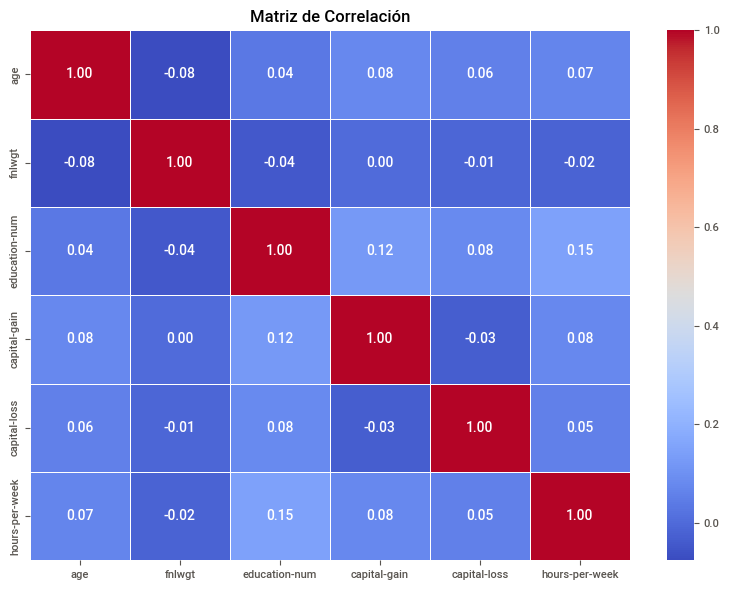


ANÁLISIS COMPLETADO CON ÉXITO.


In [19]:
# ==========================================
# EJEMPLO DE USO CON EL DATASET ADULT.CSV
# ==========================================

# 1. Cargar el dataset (reemplazar '?' por NaN que es como vienen los nulos en adult.csv)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

df_adult = pd.read_csv(url, names=columns, na_values=" ?", skipinitialspace=True)

# 2. Instanciar la clase y ejecutar run_analysis() en una sola línea
eda = AutoEDA(df_adult, target_col='income')
eda.run_analysis()

# 3.2 Crear artchivo .PY

In [20]:
from google.colab import files
files.download("herramientas_eda.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 3.3 Uso de artchivo .PY

INICIANDO ANÁLISIS AUTOMÁTICO DE DATOS (32561 filas, 15 columnas)
=== 1. DIAGNÓSTICO DE CALIDAD DE DATOS ===
 Filas duplicadas: 24 (0.07%)
 No se encontraron valores nulos (NaN/None).

=== 2. RESUMEN ESTADÍSTICO ===
Variables numéricas (6): ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Variables categóricas (9): ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country', 'income']

Estadísticas de variables numéricas:
                         mean            std      min       50%        max
age                 38.581647      13.640433     17.0      37.0       90.0
fnlwgt          189778.366512  105549.977697  12285.0  178356.0  1484705.0
education-num       10.080679       2.572720      1.0      10.0       16.0
capital-gain      1077.648844    7385.292085      0.0       0.0    99999.0
capital-loss        87.303830     402.960219      0.0       0.0     4356.0
hours-per-week      40.437456      12.347

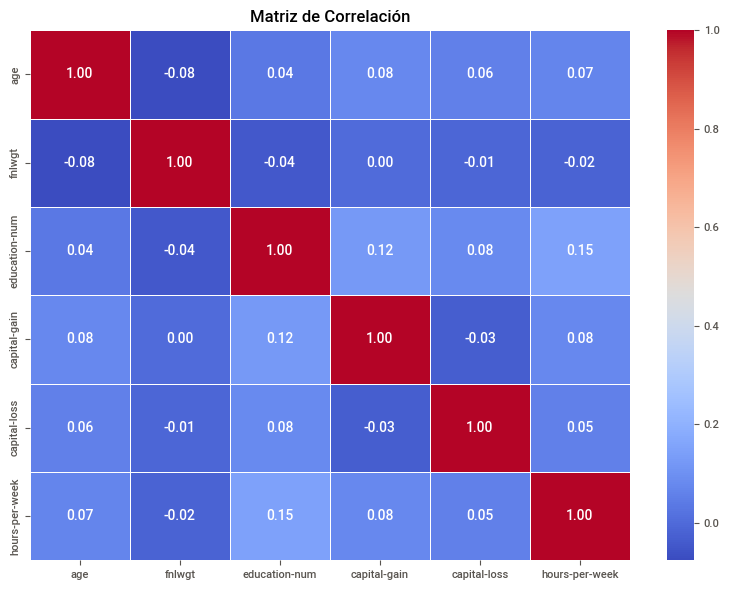


ANÁLISIS COMPLETADO CON ÉXITO.


In [21]:
import pandas as pd
# Importas tu clase desde el archivo que subiste
from herramientas_eda import AutoEDA

# 1. Cargas tus datos
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
columns = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status", "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]
df_adult = pd.read_csv(url, names=columns, na_values=" ?", skipinitialspace=True)

# 2. Tu EDA en dos líneas de código limpias
eda = AutoEDA(df_adult, target_col='income')
eda.run_analysis()
